# Лабораторная работа 1. Анализ сложности алгоритмов

**Опора:** лекции 1–2.

Реализовать требуется только три функции. Генерация массивов, подсчёт обращений
к элементам, измерение времени и графики уже готовы и лежат в пакете `labkit`
рядом с ноутбуком.

Эксперименты запускаются после того, как пройдены тесты.

In [1]:
import sys
from pathlib import Path

for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "labkit").is_dir():
        sys.path.insert(0, str(candidate))
        break

import labkit as lk

print("Режим:", lk.CONFIG.name, "| размеры массивов:", lk.sizes())

Matplotlib is building the font cache; this may take a moment.


Режим: быстрый | размеры массивов: [10, 100, 1000, 10000]


/Users/sonkxx/DSA_IDU_26/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Задача 1. Линейный поиск

Найти в массиве позицию заданного значения, просматривая элементы подряд.

- **Вход:** массив целых чисел и искомое значение.
- **Выход:** индекс любого вхождения значения; если значения нет — `-1`.

In [2]:

def linear_search(arr, target):
    """Индекс любого вхождения target в arr или -1, если его нет."""
    for i, value in enumerate(arr):
        if value == target:
            return i
    return -1


In [3]:
lk.check_search(linear_search, "Линейный поиск")

Линейный поиск
  [ok]   массив длины 0, поиск 5
    Input: {'arr': [], 'target': 5}
    Output: -1
    Expected: -1
  [ok]   массив длины 1, поиск 5
    Input: {'arr': [5], 'target': 5}
    Output: 0
    Expected: {'любой из индексов': [0]}
  [ok]   массив длины 1, поиск 10
    Input: {'arr': [5], 'target': 10}
    Output: -1
    Expected: -1
  [ok]   массив длины 4, поиск 1
    Input: {'arr': [4, 1, 3, 2], 'target': 1}
    Output: 1
    Expected: {'любой из индексов': [1]}
  [ok]   массив длины 4, поиск 4
    Input: {'arr': [4, 1, 3, 2], 'target': 4}
    Output: 0
    Expected: {'любой из индексов': [0]}
  [ok]   массив длины 4, поиск 3
    Input: {'arr': [4, 1, 3, 2], 'target': 3}
    Output: 2
    Expected: {'любой из индексов': [2]}
  [ok]   массив длины 4, поиск 100
    Input: {'arr': [4, 1, 3, 2], 'target': 100}
    Output: -1
    Expected: -1
  [ok]   массив длины 4, поиск -5
    Input: {'arr': [5, -10, 0, -5], 'target': -5}
    Output: 3
    Expected: {'любой из индексов': [3]}

## Задача 2. Двоичный поиск

Решить ту же задачу на массиве, отсортированном по неубыванию, сокращая
рассматриваемый участок вдвое на каждом шаге.

- **Вход:** отсортированный массив целых чисел и искомое значение.
- **Выход:** индекс любого вхождения значения; если значения нет — `-1`.
- **Требование:** за одну итерацию значение из массива читается один раз.

In [4]:

def binary_search(arr, target):
    """Индекс любого вхождения target в отсортированном arr или -1."""
    left = 0
    right = len(arr) - 1

    while left <= right:
        mid = (left + right) // 2
        value = arr[mid]

        if value == target:
            return mid
        elif value < target:
            left = mid + 1
        else:
            right = mid - 1

    return -1


In [ ]:
lk.check_search(binary_search, "Двоичный поиск", expect_logarithmic=True)

Двоичный поиск
  [ok]   массив длины 0, поиск 5
    Input: {'arr': [], 'target': 5}
    Output: -1
    Expected: -1
  [ok]   массив длины 1, поиск 5
    Input: {'arr': [5], 'target': 5}
    Output: 0
    Expected: {'любой из индексов': [0]}
  [ok]   массив длины 1, поиск 10
    Input: {'arr': [5], 'target': 10}
    Output: -1
    Expected: -1
  [ok]   массив длины 4, поиск 1
    Input: {'arr': [1, 2, 3, 4], 'target': 1}
    Output: 0
    Expected: {'любой из индексов': [0]}
  [ok]   массив длины 4, поиск 4
    Input: {'arr': [1, 2, 3, 4], 'target': 4}
    Output: 3
    Expected: {'любой из индексов': [3]}
  [ok]   массив длины 4, поиск 3
    Input: {'arr': [1, 2, 3, 4], 'target': 3}
    Output: 2
    Expected: {'любой из индексов': [2]}
  [ok]   массив длины 4, поиск 100
    Input: {'arr': [1, 2, 3, 4], 'target': 100}
    Output: -1
    Expected: -1
  [ok]   массив длины 4, поиск -5
    Input: {'arr': [-10, -5, 0, 5], 'target': -5}
    Output: 1
    Expected: {'любой из индексов': [1]}

## Задача 3. Палиндром

Определить, читается ли строка одинаково слева направо и справа налево.

- **Вход:** строка.
- **Выход:** `True`, если строка — палиндром, иначе `False`.
- **Требования:** решение рекурсивное; циклы и срезы запрещены; сравнение идёт
  с двух концов строки к середине.

```text
Вход:  "level"      Выход: True
Вход:  "algorithm"  Выход: False
Вход:  ""           Выход: True
```

In [6]:

def is_palindrome(text, left=0, right=None):
    """True, если text читается одинаково в обе стороны."""
    if right is None:
        right = len(text) - 1

    if left >= right:
        return True

    if text[left] != text[right]:
        return False

    return is_palindrome(text, left + 1, right - 1)


In [7]:
lk.check_palindrome(is_palindrome)

Палиндром
  [ok]   проверка палиндрома
    Input: {'text': ''}
    Output: True
    Expected: True
  [ok]   проверка палиндрома
    Input: {'text': 'a'}
    Output: True
    Expected: True
  [ok]   проверка палиндрома
    Input: {'text': 'aa'}
    Output: True
    Expected: True
  [ok]   проверка палиндрома
    Input: {'text': 'ab'}
    Output: False
    Expected: False
  [ok]   проверка палиндрома
    Input: {'text': 'aba'}
    Output: True
    Expected: True
  [ok]   проверка палиндрома
    Input: {'text': 'abba'}
    Output: True
    Expected: True
  [ok]   проверка палиндрома
    Input: {'text': 'abc'}
    Output: False
    Expected: False
  [ok]   проверка палиндрома
    Input: {'text': 'level'}
    Output: True
    Expected: True
  [ok]   проверка палиндрома
    Input: {'text': 'algorithm'}
    Output: False
    Expected: False
  [ok]   проверка палиндрома
    Input: {'text': '123454321'}
    Output: True
    Expected: True
  [ok]   проверка палиндрома
    Input: {'text': '123456

In [8]:
SEARCHES = {"Линейный поиск": linear_search, "Двоичный поиск": binary_search}
search_cases = lk.search_cases_table(SEARCHES)

Поиск: время и обращения: 100%|██████████| 104/104 [00:01<00:00, 102.86опыт/s]


## Эксперимент 1. Неуспешный поиск

Массив содержит `0, …, n−1`, искомое значение — `n`.

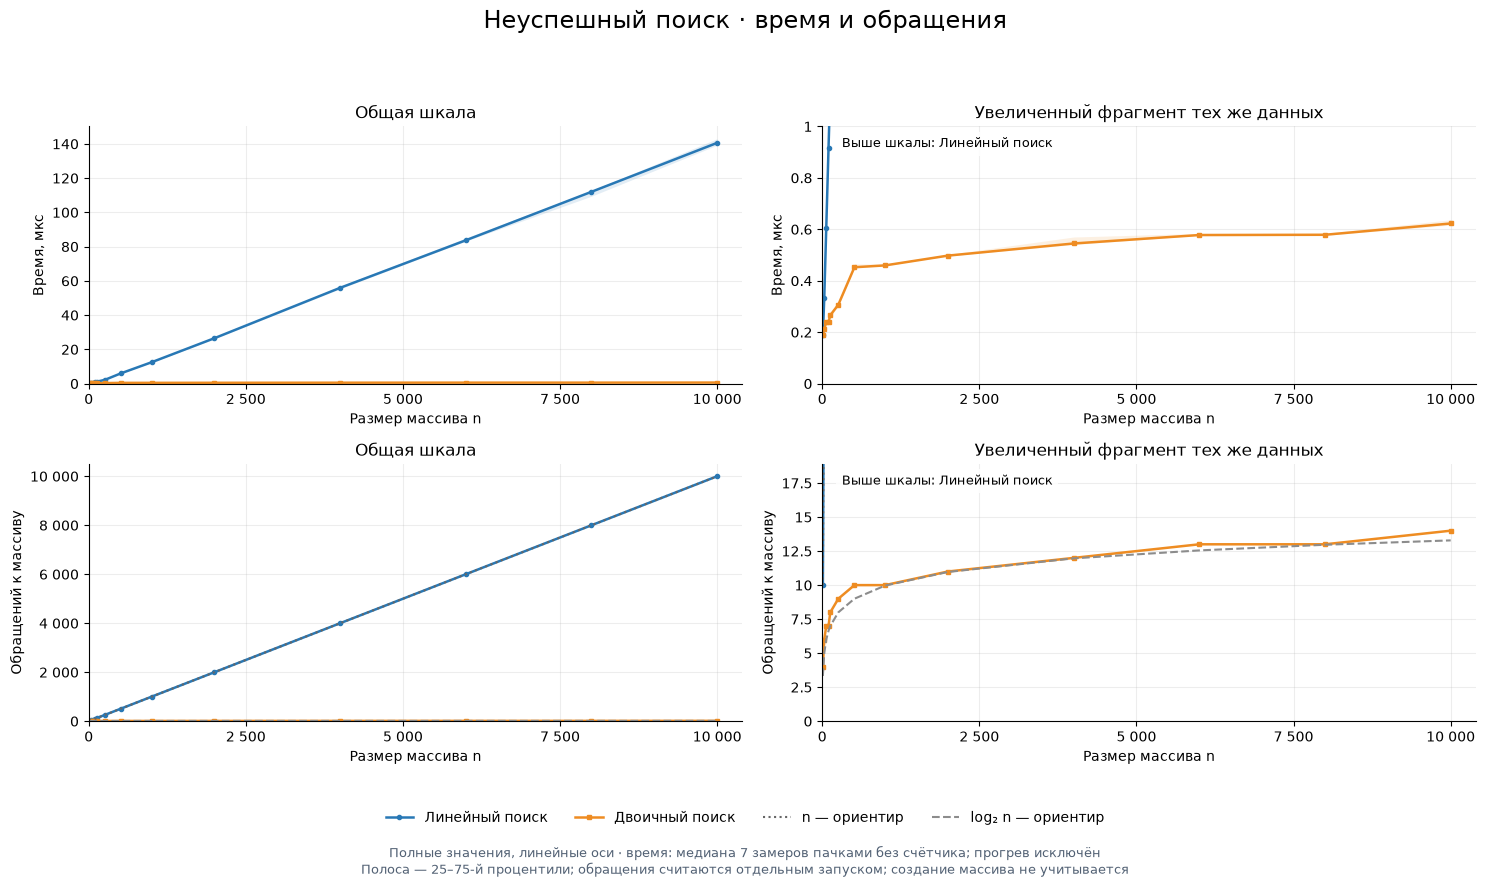

In [10]:
lk.plot_search_overview(search_cases);

## Эксперимент 2. Позиция искомого элемента

Один отсортированный массив, три случая: значение в начале, в середине
и в конце. Середина — индекс `(n−1)//2`. Случай отсутствующего элемента
рассмотрен в предыдущем эксперименте.

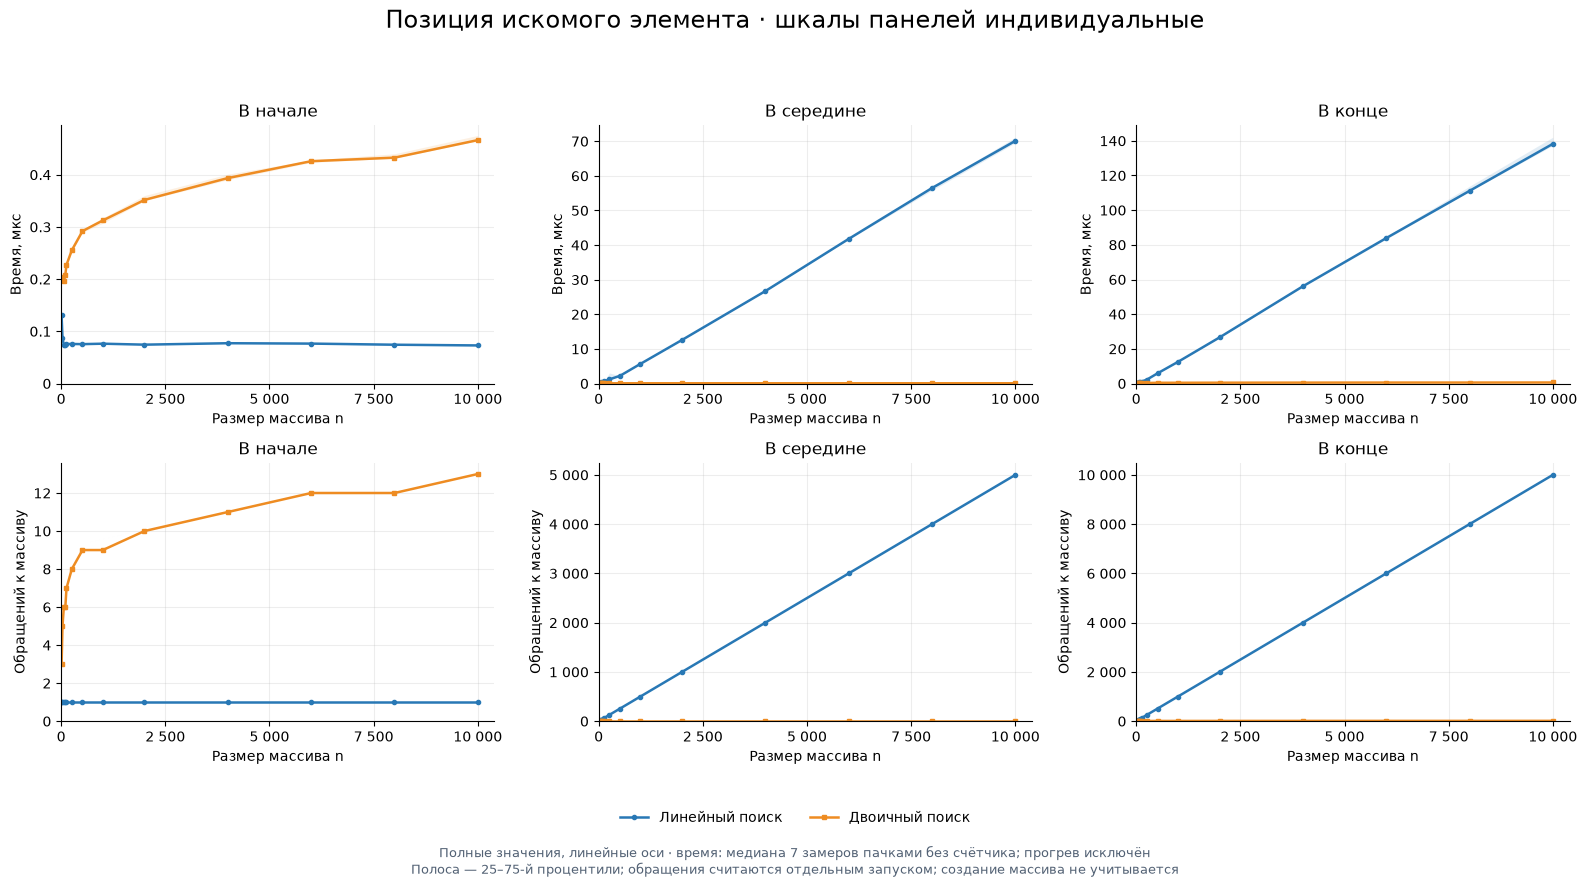

In [11]:
lk.plot_search_positions(search_cases);

## Самостоятельные выводы

1. Почему при расположении цели в начале массива время линейного поиска почти не зависит от размера массива, а двоичный поиск всё равно выполняет несколько шагов?
Если нужный элемент находится в самом начале массива, линейный поиск находит его сразу, за одно сравнение. Двоичный поиск сначала проверяет середину массива, поэтому ему может понадобиться ещё несколько шагов, чтобы найти нужное число.
2. Почему середина массива является особым случаем для двоичного поиска? Всегда ли элемент «в середине» будет найден за первое обращение?

Середина является особым случаем, потому что двоичный поиск сначала проверяет именно средний элемент. Если искомое число находится на этой позиции, то оно сразу находится за один шаг. Но если число просто находится где-то рядом с серединой, то потребуется больше шагов.

3. Почему случаи «элемент в конце» и «элемент отсутствует» близки для линейного поиска? Чем обработка этих случаев отличается у двоичного поиска?

При линейном поиске, если число находится в конце массива, алгоритму приходится почти всё просмотреть. Если числа вообще нет, он проверяет весь массив. При двоичном поиске в обоих случаях область поиска постепенно уменьшается в два раза, поэтому он работает быстрее.

4. Почему двоичный поиск требует упорядоченных данных? Что именно перестаёт быть верным без этого условия?

Двоичный поиск работает только с отсортированным массивом, потому что он сравнивает искомое число со средним элементом и решает, в какой половине продолжать поиск. Если массив не отсортирован, нельзя понять, в какой половине находится нужное число, и алгоритм может его пропустить.

5. Каковы базовый случай и рекурсивный переход у проверки палиндрома? Почему каждый переход приближает алгоритм к завершению?

Базовый случай -это когда строка имеет длину 0 или 1, что означает, что она является палиндромом. Рекурсивный переход — это проверка первого и последнего символов строки, и если они совпадают, алгоритм продолжает проверку оставшейся части строки. Каждый переход уменьшает размер строки на 2, поэтому алгоритм приближается к базовому случаю.